# 04 — Modelling, Evaluasi, dan Konklusi
## Klasifikasi Multikelas Covertype

Notebook ini membangun dan membandingkan model klasifikasi. Bagian evaluasi dan konklusi disertakan pada notebook ini agar alur proyek sesuai panduan, yang meminta hasil evaluasi dan jawaban atas pertanyaan Business Understanding.

## 1. Import library

In [1]:
from pathlib import Path
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid")

## 2. Memuat data hasil preprocessing

Prioritasnya adalah membaca `covtype_preprocessed_split.npz` yang dihasilkan notebook 03. Jika file tersebut belum tersedia, kode akan memuat `covtype.data` dan mengulang transformasi serta split dengan parameter yang sama.

In [2]:
PREPROCESSED_PATH = Path("covtype_preprocessed_split.npz")

if PREPROCESSED_PATH.exists():
    with np.load(PREPROCESSED_PATH, allow_pickle=False) as saved:
        X_train = saved["X_train"]
        X_test = saved["X_test"]
        y_train = saved["y_train"]
        y_test = saved["y_test"]
        feature_names = saved["feature_names"].tolist()
    print("Menggunakan hasil preprocessing dari:", PREPROCESSED_PATH.resolve())
else:
    print("File hasil preprocessing tidak ditemukan. Memproses ulang dari covtype.data.")
    NUMERIC_FEATURES = [
        "Elevation", "Aspect", "Slope", "Horizontal_Distance_To_Hydrology",
        "Vertical_Distance_To_Hydrology", "Horizontal_Distance_To_Roadways",
        "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
        "Horizontal_Distance_To_Fire_Points"
    ]
    WILDERNESS_COLS = [f"Wilderness_Area{i}" for i in range(1, 5)]
    SOIL_COLS = [f"Soil_Type{i}" for i in range(1, 41)]
    TARGET_COL = "Cover_Type"
    COLUMNS = NUMERIC_FEATURES + WILDERNESS_COLS + SOIL_COLS + [TARGET_COL]

    candidates = [
        Path("covtype.data"), Path("data") / "covtype.data",
        Path("../covtype.data"), Path("../data") / "covtype.data"
    ]
    data_path = next((p for p in candidates if p.exists()), None)
    if data_path is None:
        raise FileNotFoundError(
            "Letakkan covtype_preprocessed_split.npz (hasil notebook 03) "
            "atau covtype.data di folder notebook / subfolder data/."
        )

    raw = pd.read_csv(data_path, header=None, names=COLUMNS)
    if raw.isna().sum().sum() > 0:
        raise ValueError("Ditemukan missing value; selesaikan cleaning terlebih dahulu.")
    raw = raw.drop_duplicates().copy()

    angle_rad = np.deg2rad(raw["Aspect"])
    raw["Aspect_sin"] = np.sin(angle_rad)
    raw["Aspect_cos"] = np.cos(angle_rad)
    raw = raw.drop(columns=["Aspect"])

    X = raw.drop(columns=[TARGET_COL])
    y = raw[TARGET_COL].astype(int)

    X_train_df, X_test_df, y_train_s, y_test_s = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )
    selector = VarianceThreshold(threshold=0.0)
    X_train = selector.fit_transform(X_train_df)
    X_test = selector.transform(X_test_df)
    y_train = y_train_s.to_numpy()
    y_test = y_test_s.to_numpy()
    feature_names = X_train_df.columns[selector.get_support()].tolist()

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("Jumlah fitur  :", len(feature_names))
print("Kelas train   :", np.unique(y_train))
print("Kelas test    :", np.unique(y_test))

Menggunakan hasil preprocessing dari: C:\Users\parsey\Documents\GitHub\123240182_Muh_Naufal_Alfarisi_IF_C_PROJEK_DATA_SCIENCE\covtype_preprocessed_split.npz
Ukuran X_train: (464809, 55)
Ukuran X_test : (116203, 55)
Jumlah fitur  : 55
Kelas train   : [1 2 3 4 5 6 7]
Kelas test    : [1 2 3 4 5 6 7]


### Interpretasi data modelling

Notebook menggunakan **464.809 observasi training**, **116.203 observasi testing**, dan **55 fitur**. Seluruh tujuh kelas muncul pada kedua bagian. File preprocessing yang sama dipakai agar evaluasi modelling konsisten dengan notebook 03.

## 3. Menetapkan baseline dan model pembanding

Model yang dibandingkan:

1. **Dummy Classifier (most frequent):** baseline sederhana yang selalu memprediksi kelas mayoritas. Ini membantu menunjukkan mengapa accuracy saja dapat menyesatkan.
2. **Decision Tree:** model pohon keputusan yang relatif mudah diinterpretasikan.
3. **Random Forest:** ensemble beberapa pohon keputusan. `class_weight="balanced_subsample"` membantu memberi bobot lebih besar pada kelas yang lebih jarang pada setiap bootstrap sample.

Parameter dibatasi agar eksperimen pada dataset besar tetap lebih terkelola. Waktu training bergantung pada spesifikasi komputer. Jika Random Forest terlalu lama, jumlah pohon dapat diturunkan untuk eksperimen awal, lalu dicatat sebagai perubahan konfigurasi.

In [3]:
models = {
    "Dummy (majority baseline)": DummyClassifier(strategy="most_frequent"),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=25,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=25,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42,
        max_samples=0.8
    )
}

### Alasan pemilihan model dan konfigurasi

- **DummyClassifier (`most_frequent`)** menjadi baseline minimum. Model ini selalu menebak kelas yang paling sering muncul, sehingga menunjukkan performa yang bisa dicapai tanpa mempelajari hubungan fitur.
- **Decision Tree** dipakai sebagai model pohon tunggal yang relatif mudah dijelaskan. `max_depth=25` dan `min_samples_leaf=5` membatasi kompleksitas agar pohon tidak tumbuh tanpa batas. `class_weight="balanced"` memberi bobot lebih besar pada kelas yang jarang.
- **Random Forest** menggabungkan banyak pohon yang dilatih pada sampel bootstrap dan subset fitur. Penggabungan banyak pohon biasanya mengurangi variansi dibanding satu pohon. `n_estimators=100` berarti 100 pohon; `max_features="sqrt"` membatasi fitur kandidat pada setiap split; `max_depth=25` dan `min_samples_leaf=2` membatasi kompleksitas. `class_weight="balanced_subsample"` menghitung bobot kelas pada setiap bootstrap sample agar kelas minoritas lebih diperhatikan. `n_jobs=-1` menggunakan seluruh core CPU yang tersedia dan `max_samples=0.8` membatasi ukuran sampel bootstrap per pohon.

Pemilihan ini menguji baseline, model sederhana, dan ensemble. Keputusan akhir harus tetap mengikuti ketentuan praktikum: algoritma yang dinilai harus termasuk materi yang telah diajarkan.

## 4. Training model

Semua model dilatih menggunakan data training yang sama. Data test tidak digunakan pada proses pelatihan.

In [4]:
trained_models = {}
training_times = {}

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    trained_models[name] = model
    training_times[name] = elapsed
    print(f"{name}: selesai dalam {elapsed:.2f} detik")

Dummy (majority baseline): selesai dalam 0.02 detik
Decision Tree: selesai dalam 4.35 detik
Random Forest: selesai dalam 10.07 detik


### Interpretasi proses training

Ketiga model awal berhasil dilatih tanpa error. Waktu training aktual ditampilkan pada output sel sebelumnya. Dummy Classifier paling cepat karena hanya menggunakan strategi tebakan kelas mayoritas. Decision Tree melatih satu pohon, sedangkan Random Forest membangun banyak pohon sehingga umumnya membutuhkan waktu lebih lama. Waktu training bergantung pada perangkat dan lingkungan komputasi; kualitas prediksi pada metrik yang sesuai tetap menjadi pertimbangan utama.

## 5. Evaluasi dan perbandingan model

Macro-F1 menjadi metrik utama karena menghitung F1 setiap kelas dengan bobot sama. Balanced accuracy dan recall macro juga membantu menilai kemampuan model pada kelas minoritas.

In [5]:
CLASS_NAMES = [
    "Spruce/Fir", "Lodgepole Pine", "Ponderosa Pine",
    "Cottonwood/Willow", "Aspen", "Douglas-fir", "Krummholz"
]
LABELS = [1, 2, 3, 4, 5, 6, 7]

results = []
predictions = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision Macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall Macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 Macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 Weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "Training Time (s)": training_times[name]
    })

results_df = pd.DataFrame(results).sort_values("F1 Macro", ascending=False)
display(results_df.round(4))

,Model,Accuracy,Balanced Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted,Training Time (s)
2,Random Forest,0.9309,0.9234,0.8788,0.9234,0.8996,0.9312,10.0666
1,Decision Tree,0.9019,0.9081,0.7889,0.9081,0.8353,0.9046,4.3532
0,Dummy (majority baseline),0.4876,0.1429,0.0697,0.1429,0.0937,0.3197,0.0186


### Interpretasi perbandingan model awal

Tabel di atas merangkum performa tiga model awal pada test split yang digunakan dalam notebook sebelumnya.

1. **Dummy Classifier** hanya menebak kelas mayoritas. Accuracy dapat terlihat cukup tinggi karena kelas mayoritas mendominasi data, tetapi Macro-F1 dan balanced accuracy menunjukkan bahwa model ini gagal mengenali kelas-kelas lain secara seimbang.
2. **Decision Tree** jauh lebih baik daripada baseline karena mempelajari pola dari fitur.
3. **Random Forest awal** menggabungkan banyak pohon dan menghasilkan Macro-F1 tertinggi di antara tiga model awal.
4. Macro-F1 yang lebih rendah daripada weighted F1 menunjukkan bahwa performa rata-rata dengan bobot sama untuk semua kelas masih lebih rendah daripada skor yang memberi bobot sesuai jumlah observasi.

**Catatan metodologis:** test split telah digunakan untuk perbandingan model awal ini. Karena itu, evaluasi test setelah tuning pada notebook ini harus dipandang sebagai evaluasi lanjutan pada split yang sama, bukan estimasi independen yang sepenuhnya baru. Eksperimen tuning sendiri memilih parameter menggunakan validation subset dari data training, bukan menggunakan test set.


## 6. Tuning hyperparameter Random Forest

Bagian ini menambahkan eksperimen untuk memilih parameter Random Forest berdasarkan hasil pengujian, bukan berdasarkan perkiraan.

**Parameter yang diuji:**

- `max_depth`: kedalaman maksimum setiap decision tree.
- `n_estimators`: jumlah decision tree yang digabungkan dalam Random Forest.

**Rancangan eksperimen:**

1. Mengambil 60.000 observasi secara stratified hanya dari `X_train`.
2. Membagi subset menjadi 80% data fit dan 20% validation.
3. Menguji sembilan kombinasi: `max_depth` = 15, 25, 35 dan `n_estimators` = 50, 100, 150.
4. Memilih kombinasi dengan Macro-F1 validation tertinggi.
5. Melatih ulang konfigurasi terpilih menggunakan seluruh data training.
6. Mengevaluasi model hasil tuning pada test set.

Parameter lain dipertahankan sama dengan konfigurasi Random Forest awal agar pengaruh dua parameter yang diuji dapat dibandingkan dengan lebih terarah. Macro-F1 digunakan untuk pemilihan parameter karena distribusi tujuh kelas tidak seimbang.



### 6.1 Menyiapkan data fit dan validation

Subset tuning diambil hanya dari data training. Pembagian dilakukan secara stratified agar proporsi tujuh kelas relatif terjaga pada data fit dan validation. Test set tidak digunakan untuk memilih hyperparameter.


In [6]:

TUNING_SEED = 42
TUNING_SUBSET_SIZE = 60_000

# Ambil subset stratified dari X_train saja.
X_tuning_subset, _, y_tuning_subset, _ = train_test_split(
    X_train,
    y_train,
    train_size=TUNING_SUBSET_SIZE,
    random_state=TUNING_SEED,
    stratify=y_train
)

# Bagi subset: 80% untuk melatih kandidat, 20% untuk validasi.
X_tuning_fit, X_tuning_valid, y_tuning_fit, y_tuning_valid = train_test_split(
    X_tuning_subset,
    y_tuning_subset,
    test_size=0.20,
    random_state=TUNING_SEED,
    stratify=y_tuning_subset
)

print("Ukuran subset tuning :", X_tuning_subset.shape)
print("Ukuran data fit      :", X_tuning_fit.shape)
print("Ukuran data validation:", X_tuning_valid.shape)
print("Random state         :", TUNING_SEED)


Ukuran subset tuning : (60000, 55)
Ukuran data fit      : (48000, 55)
Ukuran data validation: (12000, 55)
Random state         : 42



### 6.2 Menguji sembilan kombinasi parameter

Setiap kandidat dilatih menggunakan data fit dan dinilai menggunakan validation set yang sama. Nilai parameter lain dibuat tetap agar perbandingan lebih adil. `random_state=42` ditetapkan agar proses acak dapat diulang pada lingkungan dan versi library yang sama.


In [7]:

tuning_results = []

DEPTH_CANDIDATES = [15, 25, 35]
TREE_CANDIDATES = [50, 100, 150]

for depth in DEPTH_CANDIDATES:
    for n_trees in TREE_CANDIDATES:
        candidate_model = RandomForestClassifier(
            n_estimators=n_trees,
            max_depth=depth,
            min_samples_leaf=2,
            max_features="sqrt",
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=TUNING_SEED,
            max_samples=0.8
        )

        start = time.perf_counter()
        candidate_model.fit(X_tuning_fit, y_tuning_fit)
        elapsed = time.perf_counter() - start

        validation_prediction = candidate_model.predict(X_tuning_valid)

        tuning_results.append({
            "max_depth": depth,
            "n_estimators": n_trees,
            "Macro-F1 Validation": f1_score(
                y_tuning_valid,
                validation_prediction,
                average="macro",
                zero_division=0
            ),
            "Accuracy Validation": accuracy_score(
                y_tuning_valid, validation_prediction
            ),
            "Balanced Accuracy Validation": balanced_accuracy_score(
                y_tuning_valid, validation_prediction
            ),
            "Training Time (s)": elapsed
        })

tuning_results_df = pd.DataFrame(tuning_results).sort_values(
    "Macro-F1 Validation",
    ascending=False
).reset_index(drop=True)

print("Peringkat sembilan kombinasi berdasarkan Macro-F1 validation:")
display(tuning_results_df.round(4))

print("Perbandingan Macro-F1 untuk setiap kombinasi:")
tuning_pivot = tuning_results_df.pivot(
    index="max_depth",
    columns="n_estimators",
    values="Macro-F1 Validation"
)
display(tuning_pivot.round(4))


Peringkat sembilan kombinasi berdasarkan Macro-F1 validation:


,max_depth,n_estimators,Macro-F1 Validation,Accuracy Validation,Balanced Accuracy Validation,Training Time (s)
0,35,150,0.8071,0.8684,0.7868,0.9345
1,25,150,0.8047,0.8640,0.7893,0.9353
2,25,50,0.8015,0.8592,0.7890,0.3205
3,25,100,0.8013,0.8625,0.7867,0.6059
4,35,50,0.8008,0.8642,0.7811,0.3266
5,35,100,0.8005,0.8666,0.7795,0.5858
6,15,150,0.7416,0.7991,0.8058,0.7451
7,15,100,0.7384,0.7982,0.8051,0.5014
8,15,50,0.7238,0.7908,0.7951,0.2504


Perbandingan Macro-F1 untuk setiap kombinasi:


n_estimators,50,100,150
max_depth,,,
15,0.7238,0.7384,0.7416
25,0.8015,0.8013,0.8047
35,0.8008,0.8005,0.8071



### 6.3 Memilih parameter terbaik

Konfigurasi dengan Macro-F1 validation tertinggi dipilih sebagai konfigurasi terbaik. Dengan cara ini, parameter tidak dipilih secara sembarang. Hasil validation menjadi dasar pemilihan, sedangkan test set disimpan untuk evaluasi model setelah konfigurasi ditetapkan.


In [8]:

best_tuning_row = tuning_results_df.iloc[0]

BEST_MAX_DEPTH = int(best_tuning_row["max_depth"])
BEST_N_ESTIMATORS = int(best_tuning_row["n_estimators"])
BEST_VALIDATION_MACRO_F1 = float(best_tuning_row["Macro-F1 Validation"])

print("Konfigurasi terpilih:")
print(f"max_depth    : {BEST_MAX_DEPTH}")
print(f"n_estimators : {BEST_N_ESTIMATORS}")
print(f"Validation Macro-F1 : {BEST_VALIDATION_MACRO_F1:.4f}")


Konfigurasi terpilih:
max_depth    : 35
n_estimators : 150
Validation Macro-F1 : 0.8071



### 6.4 Melatih ulang dan mengevaluasi Random Forest hasil tuning

Setelah konfigurasi dipilih, model dilatih ulang menggunakan seluruh data training (`X_train`, `y_train`). Model kemudian dievaluasi pada test set. Hasilnya ditambahkan ke tabel perbandingan agar performa model awal dan model setelah tuning dapat dibaca bersama.

**Catatan:** notebook awal sudah menggunakan test split yang sama untuk membandingkan model. Karena itu, skor test setelah tuning bukan evaluasi independen yang benar-benar baru. Untuk penelitian lanjutan, evaluasi final sebaiknya menggunakan test set independen yang hanya dibuka satu kali setelah pemilihan model.


In [9]:

tuned_model = RandomForestClassifier(
    n_estimators=BEST_N_ESTIMATORS,
    max_depth=BEST_MAX_DEPTH,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42,
    max_samples=0.8
)

start = time.perf_counter()
tuned_model.fit(X_train, y_train)
tuned_training_time = time.perf_counter() - start

y_pred_tuned = tuned_model.predict(X_test)

tuned_result = {
    "Model": "Random Forest (tuned)",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred_tuned),
    "Precision Macro": precision_score(
        y_test, y_pred_tuned, average="macro", zero_division=0
    ),
    "Recall Macro": recall_score(
        y_test, y_pred_tuned, average="macro", zero_division=0
    ),
    "F1 Macro": f1_score(
        y_test, y_pred_tuned, average="macro", zero_division=0
    ),
    "F1 Weighted": f1_score(
        y_test, y_pred_tuned, average="weighted", zero_division=0
    ),
    "Training Time (s)": tuned_training_time
}

# Tambahkan model tuned ke koleksi agar analisis berikutnya memakai model ini.
tuned_model_name = "Random Forest (tuned)"
trained_models[tuned_model_name] = tuned_model
training_times[tuned_model_name] = tuned_training_time
predictions[tuned_model_name] = y_pred_tuned

# Gabungkan hasil tuned dengan tabel perbandingan model awal.
results_df = pd.concat(
    [results_df, pd.DataFrame([tuned_result])],
    ignore_index=True
).sort_values("F1 Macro", ascending=False).reset_index(drop=True)

print("Hasil Random Forest setelah tuning:")
display(pd.DataFrame([tuned_result]).round(4))

print("Tabel perbandingan seluruh model:")
display(results_df.round(4))


Hasil Random Forest setelah tuning:


,Model,Accuracy,Balanced Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted,Training Time (s)
0,Random Forest (tuned),0.9449,0.9207,0.9123,0.9207,0.9163,0.9449,15.3386


Tabel perbandingan seluruh model:


,Model,Accuracy,Balanced Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted,Training Time (s)
0,Random Forest (tuned),0.9449,0.9207,0.9123,0.9207,0.9163,0.9449,15.3386
1,Random Forest,0.9309,0.9234,0.8788,0.9234,0.8996,0.9312,10.0666
2,Decision Tree,0.9019,0.9081,0.7889,0.9081,0.8353,0.9046,4.3532
3,Dummy (majority baseline),0.4876,0.1429,0.0697,0.1429,0.0937,0.3197,0.0186


## 7. Classification report model hasil tuning

Model untuk analisis lanjutan adalah Random Forest dengan parameter yang dipilih berdasarkan Macro-F1 validation. Classification report memperlihatkan precision, recall, F1-score, dan jumlah observasi pada setiap kelas.

In [10]:
# Gunakan model hasil tuning untuk analisis lanjutan.
best_model_name = "Random Forest (tuned)"
best_model = tuned_model
y_pred_best = y_pred_tuned

print("Model untuk analisis lanjutan:", best_model_name)
print("Parameter terpilih:", {
    "max_depth": BEST_MAX_DEPTH,
    "n_estimators": BEST_N_ESTIMATORS
})
print(classification_report(
    y_test,
    y_pred_best,
    labels=LABELS,
    target_names=CLASS_NAMES,
    zero_division=0
))

Model untuk analisis lanjutan: Random Forest (tuned)
Parameter terpilih: {'max_depth': 35, 'n_estimators': 150}
                   precision    recall  f1-score   support

       Spruce/Fir       0.96      0.93      0.94     42368
   Lodgepole Pine       0.95      0.96      0.95     56661
   Ponderosa Pine       0.92      0.95      0.94      7151
Cottonwood/Willow       0.85      0.90      0.87       549
            Aspen       0.88      0.85      0.87      1899
      Douglas-fir       0.87      0.90      0.89      3473
        Krummholz       0.95      0.96      0.96      4102

         accuracy                           0.94    116203
        macro avg       0.91      0.92      0.92    116203
     weighted avg       0.95      0.94      0.94    116203



### Interpretasi classification report per kelas

Baca nilai precision, recall, dan F1-score untuk setiap kelas bersama kolom `support`.

- **Precision** menjelaskan proporsi prediksi suatu kelas yang benar.
- **Recall** menjelaskan proporsi observasi aktual suatu kelas yang berhasil ditemukan model.
- **F1-score** merangkum keseimbangan precision dan recall.
- **Support** menunjukkan jumlah observasi aktual pada kelas tersebut di test set.

Perhatikan kelas dengan support kecil. Perubahan beberapa prediksi saja dapat mengubah metrik kelas tersebut secara relatif besar. Gunakan nilai aktual yang tercetak pada classification report di atas; jangan mengasumsikan semua kelas memiliki performa yang sama.

## 8. Confusion matrix

Confusion matrix menggunakan prediksi Random Forest hasil tuning. Baris menunjukkan kelas aktual, sedangkan kolom menunjukkan kelas prediksi. Nilai diagonal adalah prediksi benar dan nilai di luar diagonal adalah kesalahan.

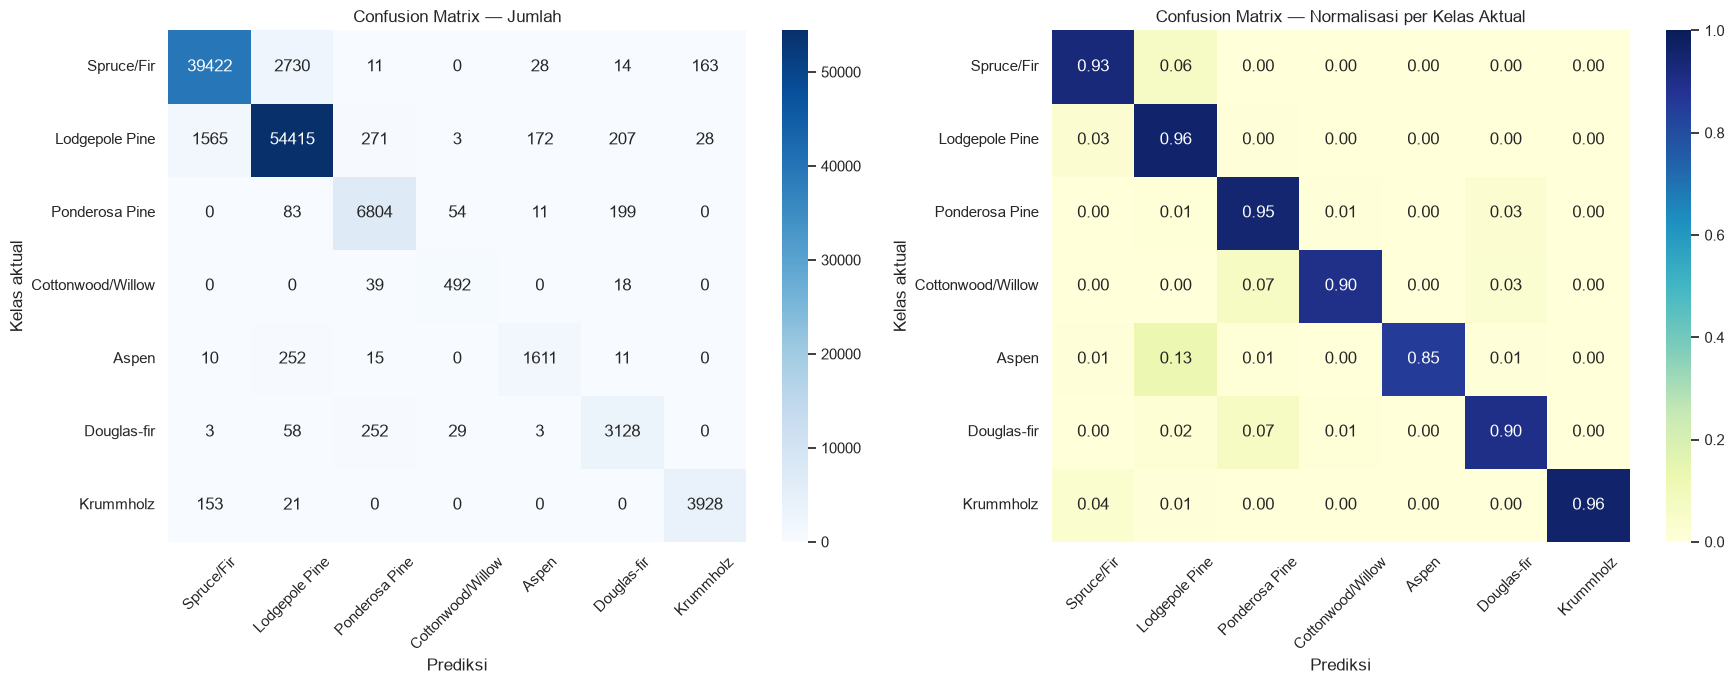

In [11]:
cm = confusion_matrix(y_test, y_pred_best, labels=LABELS)
cm_normalized = confusion_matrix(
    y_test, y_pred_best, labels=LABELS, normalize="true"
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0]
)
axes[0].set_title("Confusion Matrix — Jumlah")
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Kelas aktual")
axes[0].tick_params(axis="x", rotation=45)
axes[0].tick_params(axis="y", rotation=0)

sns.heatmap(
    cm_normalized, annot=True, fmt=".2f", cmap="YlGnBu",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1],
    vmin=0, vmax=1
)
axes[1].set_title("Confusion Matrix — Normalisasi per Kelas Aktual")
axes[1].set_xlabel("Prediksi")
axes[1].set_ylabel("Kelas aktual")
axes[1].tick_params(axis="x", rotation=45)
axes[1].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [12]:
cm_offdiag = cm.copy()
np.fill_diagonal(cm_offdiag, 0)
row_idx, col_idx = np.unravel_index(np.argmax(cm_offdiag), cm_offdiag.shape)

print(
    "Pasangan kesalahan terbanyak:",
    f"kelas aktual {LABELS[row_idx]} ({CLASS_NAMES[row_idx]})",
    "diprediksi sebagai",
    f"kelas {LABELS[col_idx]} ({CLASS_NAMES[col_idx]})",
    f"sebanyak {cm_offdiag[row_idx, col_idx]:,} observasi."
)

Pasangan kesalahan terbanyak: kelas aktual 1 (Spruce/Fir) diprediksi sebagai kelas 2 (Lodgepole Pine) sebanyak 2,730 observasi.


### Interpretasi confusion matrix

Gunakan dua panel confusion matrix untuk membaca hasil dari dua sudut:

- **Jumlah observasi:** memperlihatkan volume kesalahan absolut.
- **Normalisasi per kelas aktual:** memperlihatkan proporsi observasi pada setiap kelas yang diprediksi ke masing-masing kelas.

Sel di luar diagonal dengan angka terbesar menunjukkan pasangan kelas yang paling sering tertukar. Hasil ini menggambarkan pola kesalahan model, tetapi tidak dengan sendirinya membuktikan penyebab biologis atau geografisnya.

## 9. Feature importance

Feature importance dihitung dari Random Forest hasil tuning. Nilai ini menunjukkan kontribusi relatif fitur dalam pemisahan pada model, bukan bukti hubungan sebab-akibat.

,Feature,Importance
0,Elevation,0.236127
4,Horizontal_Distance_To_Roadways,0.104386
8,Horizontal_Distance_To_Fire_Points,0.082669
2,Horizontal_Distance_To_Hydrology,0.060849
3,Vertical_Distance_To_Hydrology,0.048543
12,Wilderness_Area4,0.047312
5,Hillshade_9am,0.038063
54,Aspect_cos,0.037525
7,Hillshade_3pm,0.032393
6,Hillshade_Noon,0.030655


Tiga fitur dengan importance tertinggi:


,Feature,Importance
0,Elevation,0.236127
4,Horizontal_Distance_To_Roadways,0.104386
8,Horizontal_Distance_To_Fire_Points,0.082669


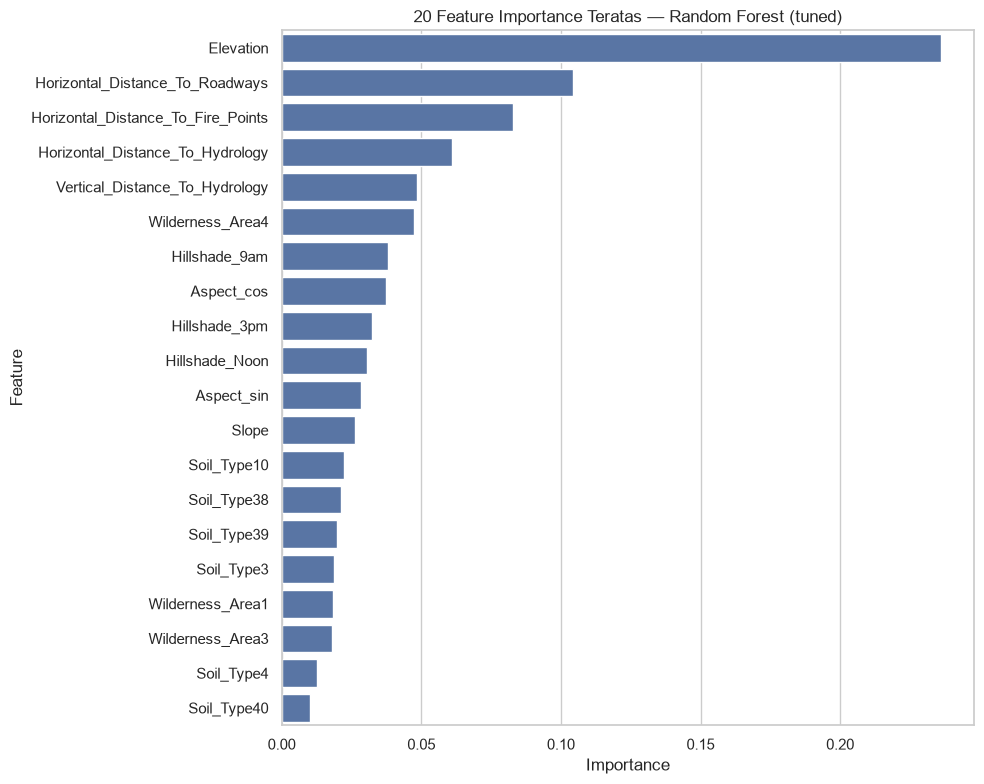

In [13]:
if hasattr(best_model, "feature_importances_"):
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": best_model.feature_importances_
    }).sort_values("Importance", ascending=False)

    display(importance_df.head(20))

    print("Tiga fitur dengan importance tertinggi:")
    display(importance_df.head(3))

    plt.figure(figsize=(10, 8))
    sns.barplot(
        data=importance_df.head(20),
        x="Importance", y="Feature"
    )
    plt.title(f"20 Feature Importance Teratas — {best_model_name}")
    plt.tight_layout()
    plt.show()
else:
    print("Model terpilih tidak menyediakan feature_importances_.")

### Interpretasi feature importance Random Forest

Perhatikan tabel dan grafik 20 fitur teratas yang dihasilkan pada sel sebelumnya. Tiga fitur pada urutan teratas merupakan fitur dengan kontribusi relatif terbesar menurut impurity-based feature importance pada model ini.

Feature importance **bukan hubungan sebab-akibat**. Nilai tersebut tidak menunjukkan bahwa perubahan suatu fitur secara langsung menyebabkan perubahan jenis tutupan hutan. Nilainya juga dapat dipengaruhi oleh korelasi antarfitur, banyaknya kategori, dan cara pohon membentuk split. Karena itu, interpretasikan sebagai kontribusi relatif dalam model yang dilatih.

## 10. Konklusi proyek

Bagian ini merangkum jawaban terhadap pertanyaan Business Understanding, hasil model, alasan pemilihan parameter, pola kesalahan, dan keterbatasan evaluasi.

In [14]:
best_row = results_df.loc[
    results_df["Model"] == "Random Forest (tuned)"
].iloc[0]

cm = confusion_matrix(y_test, y_pred_best, labels=LABELS)
per_class_recall = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)
lowest_recall_index = int(np.argmin(per_class_recall))
lowest_recall_class = LABELS[lowest_recall_index]

print("RINGKASAN HASIL RANDOM FOREST TUNED")
print("==================================")
print("Model:", best_model_name)
print(f"max_depth    : {BEST_MAX_DEPTH}")
print(f"n_estimators : {BEST_N_ESTIMATORS}")
print(f"Validation Macro-F1 : {BEST_VALIDATION_MACRO_F1:.4f}")
print(f"Accuracy            : {best_row['Accuracy']:.4f}")
print(f"Balanced Accuracy   : {best_row['Balanced Accuracy']:.4f}")
print(f"Macro-F1            : {best_row['F1 Macro']:.4f}")
print(f"Weighted F1         : {best_row['F1 Weighted']:.4f}")
print(
    f"Recall terendah     : kelas {lowest_recall_class} "
    f"({CLASS_NAMES[lowest_recall_index]}) = "
    f"{per_class_recall[lowest_recall_index]:.4f}"
)

RINGKASAN HASIL RANDOM FOREST TUNED
Model: Random Forest (tuned)
max_depth    : 35
n_estimators : 150
Validation Macro-F1 : 0.8071
Accuracy            : 0.9449
Balanced Accuracy   : 0.9207
Macro-F1            : 0.9163
Weighted F1         : 0.9449
Recall terendah     : kelas 5 (Aspen) = 0.8483


## 10.1 Kesimpulan berdasarkan hasil eksperimen

Fitur topografi dan lingkungan pada dataset Covertype digunakan untuk memprediksi tujuh kelas tutupan hutan. Random Forest dipakai sebagai model utama karena termasuk pendekatan ensemble berbasis pohon yang sesuai untuk klasifikasi multikelas.

Parameter Random Forest dipilih melalui eksperimen validation dengan membandingkan sembilan kombinasi `max_depth` dan `n_estimators`. Konfigurasi akhir ditentukan berdasarkan Macro-F1 validation, bukan dipilih secara sembarang. Hasil test dan tabel perbandingan ditampilkan secara dinamis pada sel sebelumnya.

### Makna hasil

- **Accuracy:** proporsi seluruh observasi test yang diprediksi dengan benar.
- **Balanced accuracy:** rata-rata recall tujuh kelas, sehingga tiap kelas memperoleh bobot sama.
- **Macro-F1:** rata-rata F1 tujuh kelas dengan bobot sama.
- **Classification report:** menunjukkan kelas mana yang lebih mudah atau lebih sulit dikenali.
- **Confusion matrix:** menunjukkan pasangan kelas yang paling sering tertukar.

### Keputusan preprocessing

Tidak dilakukan imputasi atau penghapusan duplikasi karena tidak ditemukan missing value maupun baris duplikat. Outlier IQR dipertahankan karena nilai ekstrem tidak otomatis merupakan kesalahan data. `Aspect` diubah menjadi sinus dan cosinus karena merupakan variabel sudut melingkar. Fitur konstan diperiksa dengan `VarianceThreshold`, tetapi tidak ada fitur yang terhapus. Scaling tidak diterapkan karena Random Forest berbasis pohon. `class_weight="balanced_subsample"` digunakan untuk memberi bobot lebih pada kelas yang jarang.

### Keterbatasan dan kehati-hatian

1. Dataset merepresentasikan cakupan geografis tertentu dan tidak otomatis mewakili semua kawasan hutan.
2. Dataset berasal dari tahun 1998; kondisi vegetasi dan lingkungan dapat berubah.
3. Data petak 30 × 30 meter berpotensi memiliki autokorelasi spasial. Random stratified split dapat menempatkan petak berdekatan pada train dan test sehingga hasil dapat lebih optimistis dibanding pengujian pada wilayah geografis baru.
4. Dataset yang digunakan tidak menyertakan koordinat eksplisit untuk melakukan spatial holdout.
5. Test split telah digunakan untuk membandingkan model awal sebelum tuning. Tuning parameter tambahan memilih konfigurasi menggunakan validation subset dari training data, tetapi skor test setelah tuning tetap merupakan evaluasi lanjutan pada split yang telah pernah diperiksa, bukan estimasi independen yang sepenuhnya baru.
6. Untuk estimasi final yang lebih kuat, tetapkan validation/cross-validation di dalam data training dan gunakan test set independen hanya sekali pada akhir eksperimen.
7. Feature importance Random Forest bersifat model-dependent dan tidak membuktikan hubungan sebab-akibat.

### Kesimpulan akhir

Pada eksperimen ini, Random Forest dengan parameter hasil tuning memberikan konfigurasi terbaik berdasarkan Macro-F1 validation di antara kombinasi yang diuji. Hasil evaluasi test disajikan sebagai hasil awal lanjutan dan perlu dibaca dengan mempertimbangkan keterbatasan penggunaan test split sebelumnya.

## 11. Referensi

1. Blackard, J. A. (1998). *Covertype* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C50K5N
2. UCI Machine Learning Repository. *Covertype*. https://archive.ics.uci.edu/dataset/31/covertype
3. Panduan Proyek Akhir Praktikum Data Science 2026/2027, Program Studi Informatika, UPN “Veteran” Yogyakarta.